# Short-lived pair reversion & spread autocorrelation

Two questions, both aimed at catching mean-reversion the strict cointegration
gate in `teamName.py` (`ADF(1) t < PAIR_ADF_T`) tends to miss:

1. **Short-lived pockets.** Over *small* runtime windows, some pairs light up as
   strongly mean-reverting for only a few windows and then fade. How long do these
   episodes actually last, and can we tell a transient flash from a persistent
   relationship *while it is happening*?

2. **Autocorrelation instead of / alongside the p-value.** The ADF test asks a
   hard yes/no (is there a unit root over the whole window?) and has poor power on
   short samples. Direct **autocorrelation measures on the spread** — the AR(1)
   coefficient, the lag-1 autocorrelation of spread *changes*, and the variance
   ratio — measure the *speed* of reversion continuously and may register partial
   or short-lived reversion the ADF gate rejects.

`teamName.py` already carries an **EPISODIC tier** built for exactly idea 1: a
short `EPISODE_LOOKBACK`-day window, a very strict `EPISODE_ADF_T` gate, and a
**causal confirmation** at an endpoint `EPISODE_CONFIRM_GAP` days earlier to
reject one-day flukes. This notebook stress-tests that mechanism (does the
confirmation actually help? §5) and asks whether the autocorrelation measures add
anything on top of it.

> Note on "high p-values": we cover both meanings. A pair can (a) be *strongly*
> mean-reverting only briefly (a short-lived low-p episode), or (b) have a **high
> ADF p-value** (the gate rejects it) yet still show autocorrelation-style
> reversion. §2 isolates group (b); §3 measures how short-lived group (a) is.

**This is analysis only — no trading strategy is built or changed.**

## 0 · Setup

We reuse `teamName.py`'s exact spread construction (OLS log-price hedge ratio)
and its vectorised `_adf_tstat`, so every "cointegration" number here is the one
the live gate would see.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import teamName as TN

CAT = ["#2a78d6","#eb6834","#008300","#4a3aa7","#eda100","#1baf7a","#e87ba4","#e34948"]
BLUE,ORANGE,GREEN,RED,VIOLET,AQUA = "#2a78d6","#eb6834","#008300","#e34948","#4a3aa7","#1baf7a"
GRID,MUTED,INK = "#e1e0d9","#898781","#0b0b0b"
SEQ = LinearSegmentedColormap.from_list("seq",["#f4f3ef","#9ec5f4",BLUE,"#0d366b"])
DIV = LinearSegmentedColormap.from_list("div",[BLUE,"#f0efec",RED])
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","axes.edgecolor":MUTED,
    "axes.labelcolor":INK,"text.color":INK,"xtick.color":MUTED,"ytick.color":MUTED,
    "axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.color":GRID,
    "grid.linewidth":.7,"axes.titleweight":"bold","figure.dpi":110,"font.size":9})

prices = pd.read_csv("prices.txt", sep=r"\s+"); TICK=list(prices.columns)
LP = np.log(prices.values.T); ndays = LP.shape[1]
PI, PJ = TN._PI, TN._PJ; NP = len(PI)
pair_name = np.array([f"{TICK[i]}~{TICK[j]}" for i,j in zip(PI,PJ)])
print(f"{LP.shape[0]} instruments, {ndays} days, {NP} pairs")
print(f"file EPISODIC tier: lookback={TN.EPISODE_LOOKBACK}d  gate t<{TN.EPISODE_ADF_T}  "
      f"confirm t<{TN.EPISODE_CONFIRM_T} @ {TN.EPISODE_CONFIRM_GAP}d earlier  "
      f"half-life {TN.EPISODE_HL_MIN}-{TN.EPISODE_HL_MAX}d")
print(f"file CORE tier:     lookback={TN.PAIR_LOOKBACK}d  gate t<{TN.CORE_ADF_T}  center={TN.CORE_CENTER}d")

51 instruments, 750 days, 1225 pairs
file EPISODIC tier: lookback=75d  gate t<-4.25  confirm t<-3.75 @ 10d earlier  half-life 1.5-20.0d
file CORE tier:     lookback=250d  gate t<-2.9  center=60d


## 1 · The spread + the mean-reversion toolbox

For a window of log-prices we build the file's spread and then five reversion
diagnostics for **every** pair at once:

| measure | formula | mean-reverting when |
|---|---|---|
| **ADF(1) t** (the gate) | t-stat on `ρ` in `Δs=a+ρ·s₋₁+γ·Δs₋₁` | very negative |
| **AR(1) φ** | `s_t = φ·s_{t-1}` | `0≤φ<1` (smaller = faster) |
| **half-life** | `−ln2 / ln φ` | small & positive |
| **lag-1 autocorr of Δspread** `ac1` | `corr(Δs_t, Δs_{t-1})` | **negative** (corrections overshoot) |
| **variance ratio** `VR(q)` | `Var(s_{t+q}−s_t) / (q·Var(Δs))` | `< 1` |

`ac1` and `VR` are pure autocorrelation statistics — they need no unit-root
rejection, so they can flag *partial* reversion.

In [2]:
def build_spreads(LPw):
    # reuse the file's exact OLS hedge ratio; centre the spread for the measures
    beta, spread = TN._pair_regression(LPw, PI, PJ)   # (NP,), (NP, L)
    mu = spread.mean(1)                                # per-pair spread mean
    res = spread - mu[:, None]                         # mean-zero spread
    return beta, mu, res

def mr_measures(res):
    slag, snxt = res[:,:-1], res[:,1:]
    phi = (slag*snxt).sum(1) / np.maximum((slag*slag).sum(1), 1e-18)
    ds = np.diff(res, axis=1)
    d1, d2 = ds[:,:-1], ds[:,1:]
    d1c = d1 - d1.mean(1,keepdims=True); d2c = d2 - d2.mean(1,keepdims=True)
    ac1 = (d1c*d2c).sum(1) / np.sqrt(np.maximum((d1c*d1c).sum(1)*(d2c*d2c).sum(1), 1e-18))
    def vr(q):
        v1 = ds.var(1); Rq = res[:,q:] - res[:,:-q]
        return Rq.var(1) / np.maximum(q*v1, 1e-18)
    with np.errstate(divide="ignore", invalid="ignore"):
        hl = np.where((phi>0)&(phi<1), -np.log(2)/np.log(np.clip(phi,1e-9,0.999999)), np.inf)
    adf_t = TN._adf_tstat(res.T)
    z = res[:,-1] / (res.std(1)+1e-12)
    return dict(adf_t=adf_t, phi=phi, half_life=hl, ac1=ac1, vr5=vr(5), vr10=vr(10), z=z)

def hurst(x, mx=25):
    lags=np.arange(2,mx); tau=[np.std(x[l:]-x[:-l]) for l in lags]
    return float(np.polyfit(np.log(lags), np.log(np.maximum(tau,1e-12)),1)[0])
print("toolbox ready.")

toolbox ready.


## 2 · ADF gate vs autocorrelation on a small window

Over the file's **short `EPISODE_LOOKBACK`-day window** ending at day 500, compute
the gate (ADF t) and the autocorrelation measures for all pairs. The scatter below
asks: do pairs the strict episodic gate **rejects** (ADF t not negative enough)
still show autocorrelation-style reversion (negative `ac1`, `VR<1`)? Those are the
"high-p but mean-reverting" pairs the second idea is about.

W=75: episodic gate (t<-4.25) passes 3 pairs.
Gate-REJECTED but autocorr-reverting (ac1<-0.15 & VR5<0.9): 159 pairs


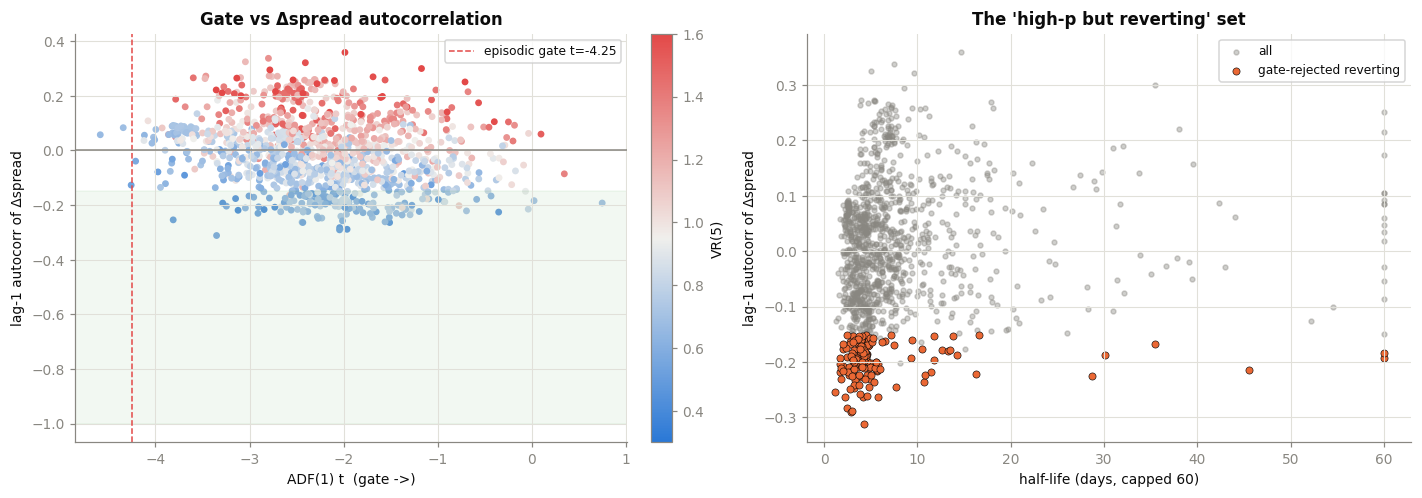

,adf_t,phi,half_life,ac1,vr5,z,pair,gate_pass,ac_revert
111,-3.350,0.850,4.279,-0.311,0.604,-0.840,SRNA~RTTH,False,True
601,-2.043,0.786,2.879,-0.291,0.556,0.943,HRET~MDGI,False,True
741,-1.963,0.795,3.022,-0.289,0.498,-2.042,SPLZ~CCNS,False,True
267,-2.042,0.753,2.448,-0.282,0.519,2.337,OTCS~AETS,False,True
310,-1.511,0.849,4.229,-0.264,0.504,-2.453,HETT~AETS,False,True
620,-2.433,0.734,2.242,-0.264,0.581,1.528,HRET~BLBT,False,True
309,-2.442,0.888,5.824,-0.263,0.773,-0.801,HETT~HRND,False,True
596,-1.559,0.860,4.579,-0.261,0.684,1.203,HRET~DIHO,False,True
711,-2.012,0.836,3.879,-0.257,0.637,-0.229,RTTH~MTNS,False,True
131,-3.812,0.545,1.143,-0.254,0.556,1.025,SRNA~HRND,False,True


In [3]:
W = TN.EPISODE_LOOKBACK
GATE = TN.EPISODE_ADF_T
beta, mu, res = build_spreads(LP[:, 500-W:500])
mm = mr_measures(res)
df = pd.DataFrame({k: mm[k] for k in ["adf_t","phi","half_life","ac1","vr5","z"]})
df["pair"] = pair_name
df["gate_pass"] = df.adf_t < GATE
# 'high-p but reverting': gate REJECTS, yet Δspread autocorr negative and VR<1
df["ac_revert"] = (df.ac1 < -0.15) & (df.vr5 < 0.9)
hi_p_rev = df[(~df.gate_pass) & df.ac_revert]
print(f"W={W}: episodic gate (t<{GATE}) passes {int(df.gate_pass.sum())} pairs.")
print(f"Gate-REJECTED but autocorr-reverting (ac1<-0.15 & VR5<0.9): {len(hi_p_rev)} pairs")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sc = ax[0].scatter(df.adf_t, df.ac1, c=df.vr5.clip(0.3,1.6), cmap=DIV, s=12, vmin=0.3, vmax=1.6)
ax[0].axvline(GATE, color=RED, ls="--", lw=1, label=f"episodic gate t={GATE}")
ax[0].axhline(0, color=MUTED, lw=1)
ax[0].axhspan(-1, -0.15, xmin=0, xmax=1, color=GREEN, alpha=.05)
ax[0].set_xlabel("ADF(1) t  (gate ->)"); ax[0].set_ylabel("lag-1 autocorr of Δspread")
ax[0].set_title("Gate vs Δspread autocorrelation"); ax[0].legend(fontsize=8)
fig.colorbar(sc, ax=ax[0], fraction=.046, pad=.04, label="VR(5)")
# where do gate-rejected reverting pairs sit in half-life?
ax[1].scatter(df.half_life.clip(0,60), df.ac1, s=10, color=MUTED, alpha=.4, label="all")
ax[1].scatter(hi_p_rev.half_life.clip(0,60), hi_p_rev.ac1, s=22, color=ORANGE, edgecolor=INK, lw=.4, label="gate-rejected reverting")
ax[1].set_xlabel("half-life (days, capped 60)"); ax[1].set_ylabel("lag-1 autocorr of Δspread")
ax[1].set_title("The 'high-p but reverting' set"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
hi_p_rev.sort_values("ac1").head(10).round(3)

## 3 · How short-lived are the episodes?

Roll a small window forward through runtime (step 5 days) and, at each step, flag
every pair each method calls "mean-reverting". To compare methods **fairly**, all
thresholds are calibrated to the **same 5% false-positive rate** under a
random-walk null at this window length. Then, per pair, we measure how many
*consecutive* windows a flag survives — the **episode length**.

5% one-sided reversion thresholds at W=75:  ADF t<-3.42   ac1<-0.22   VR5<0.55


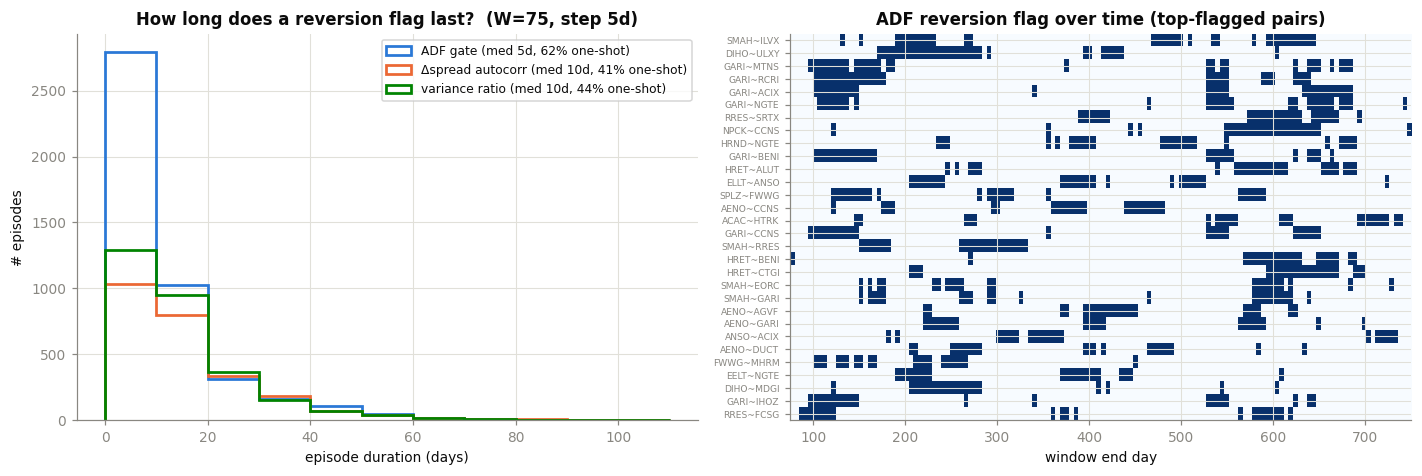

ADF gate            : 9456 flags, 4477 episodes, median 5d, 62% last a single window
Δspread autocorr    : 7314 flags, 2511 episodes, median 10d, 41% last a single window
variance ratio      : 7630 flags, 2906 episodes, median 10d, 44% last a single window


In [4]:
def mc_null(W, n=6000, seed=0):
    rng = np.random.default_rng(seed)
    a = np.cumsum(rng.standard_normal((n,W)),1); b = np.cumsum(rng.standard_normal((n,W)),1)
    ac = a-a.mean(1,keepdims=True); bc = b-b.mean(1,keepdims=True)
    beta = (ac*bc).sum(1)/np.maximum((bc*bc).sum(1),1e-18)
    r = ac - beta[:,None]*bc
    return mr_measures(r)

nul = mc_null(W)
crit = dict(adf_t=np.percentile(nul["adf_t"], 5),      # more negative than this
            ac1  =np.percentile(nul["ac1"], 5),        # more negative than this
            vr5  =np.percentile(nul["vr5"], 5))        # smaller than this
print(f"5% one-sided reversion thresholds at W={W}:  "
      f"ADF t<{crit['adf_t']:.2f}   ac1<{crit['ac1']:.2f}   VR5<{crit['vr5']:.2f}")

starts = list(range(0, ndays - W + 1, 5))
ends = [s+W for s in starts]
flags = {m: np.zeros((NP, len(starts)), bool) for m in ["adf_t","ac1","vr5"]}
for c, s in enumerate(starts):
    _,_,r = build_spreads(LP[:, s:s+W]); mm = mr_measures(r)
    flags["adf_t"][:,c] = mm["adf_t"] < crit["adf_t"]
    flags["ac1"][:,c]   = mm["ac1"]   < crit["ac1"]
    flags["vr5"][:,c]   = mm["vr5"]   < crit["vr5"]

def episode_lengths(F):
    out = []
    for row in F:
        run = 0
        for v in row:
            if v: run += 1
            elif run: out.append(run); run = 0
        if run: out.append(run)
    return np.array(out) if out else np.array([0])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
colors = {"adf_t":BLUE, "ac1":ORANGE, "vr5":GREEN}
labels = {"adf_t":"ADF gate", "ac1":"Δspread autocorr", "vr5":"variance ratio"}
for m in flags:
    el = episode_lengths(flags[m])
    frac1 = (el==1).mean()
    ax[0].hist(el*5, bins=np.arange(0,120,10), histtype="step", lw=1.8, color=colors[m],
               label=f"{labels[m]} (med {np.median(el)*5:.0f}d, {frac1:.0%} one-shot)")
ax[0].set_xlabel("episode duration (days)"); ax[0].set_ylabel("# episodes")
ax[0].set_title(f"How long does a reversion flag last?  (W={W}, step 5d)")
ax[0].legend(fontsize=8)

# heatmap: reversion field (ADF) for the 30 most-often-flagged pairs
freq = flags["adf_t"].mean(1); top = np.argsort(freq)[::-1][:30]
im = ax[1].imshow(flags["adf_t"][top], aspect="auto", cmap="Blues",
                  extent=[ends[0], ends[-1], len(top)-.5, -.5], interpolation="nearest")
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels(pair_name[top], fontsize=6)
ax[1].set_xlabel("window end day"); ax[1].set_title("ADF reversion flag over time (top-flagged pairs)")
fig.tight_layout(); plt.show()

for m in flags:
    el = episode_lengths(flags[m])
    print(f"{labels[m]:20s}: {int(flags[m].sum())} flags, {len(el)} episodes, "
          f"median {np.median(el)*5:.0f}d, {(el==1).mean():.0%} last a single window")

## 4 · Responsiveness — which signal reacts first, and how short can we go?

For a few pairs, overlay the three rolling signals so we can see which one turns on
earliest at the onset of a reversion episode. Then, using the null, we check how
each measure's **noise floor** grows as the window shrinks — i.e. how short a
window each technique can tolerate before it is indistinguishable from a random
walk.

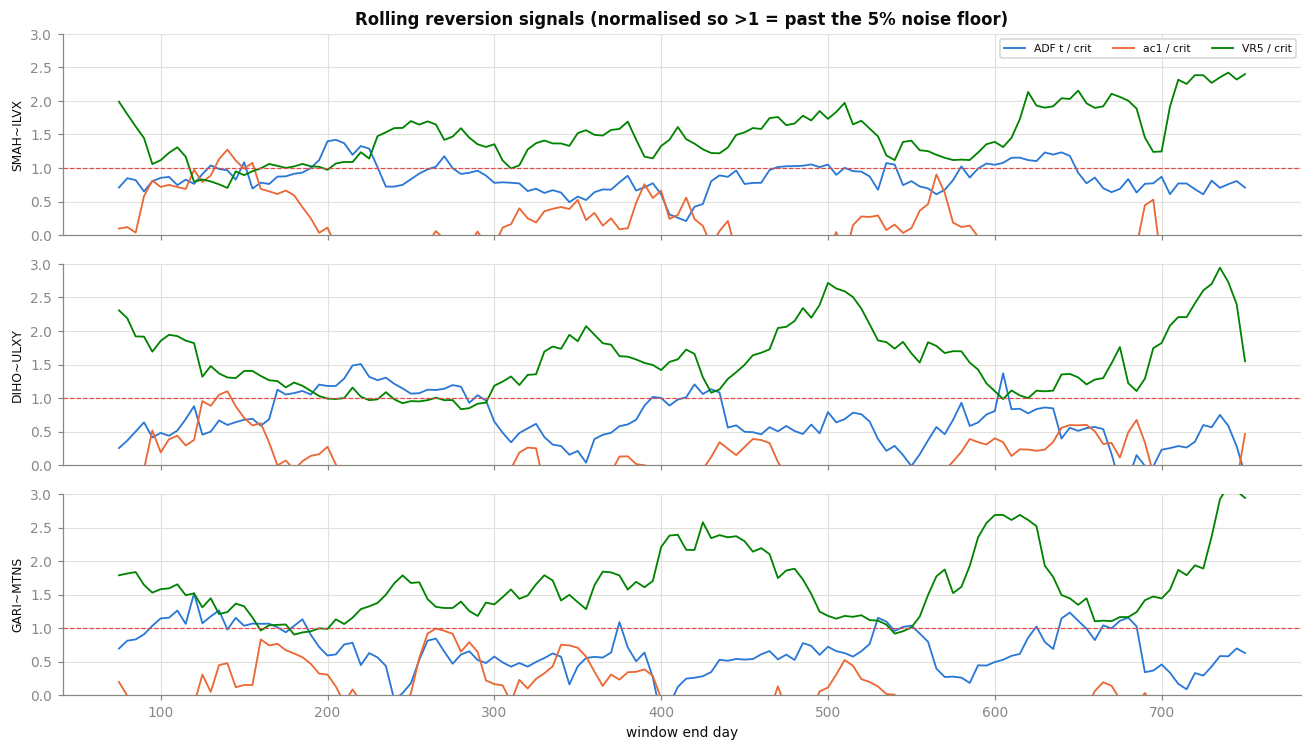

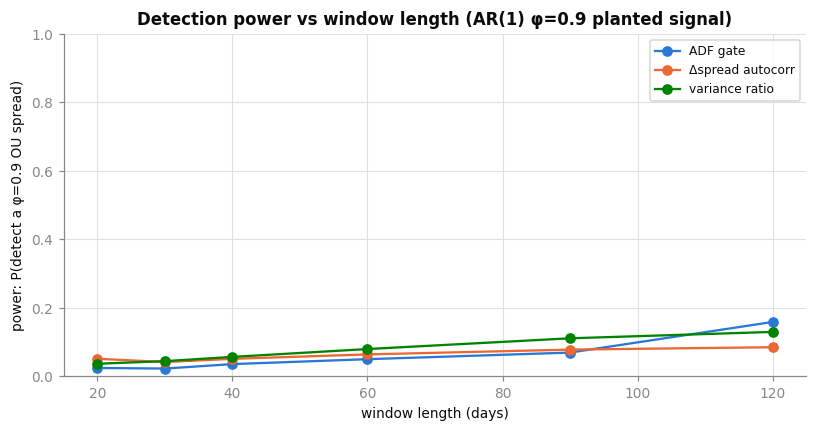

In [5]:
# (a) example pairs: rolling signals through time (one loop, normalised to 5% crit)
ex = top[:3]
sig = {int(k): {"adf_t": [], "ac1": [], "vr5": []} for k in ex}
for s in starts:
    _, _, r = build_spreads(LP[:, s:s+W]); mm = mr_measures(r)
    for k in ex:
        for m in ("adf_t","ac1","vr5"): sig[int(k)][m].append(mm[m][k])
fig, ax = plt.subplots(len(ex), 1, figsize=(12, 2.3*len(ex)), sharex=True)
axl = np.atleast_1d(ax)
for a, k in zip(axl, ex):
    a.plot(ends, np.array(sig[int(k)]["adf_t"])/crit["adf_t"], color=BLUE, lw=1.2, label="ADF t / crit")
    a.plot(ends, np.array(sig[int(k)]["ac1"])/crit["ac1"], color=ORANGE, lw=1.2, label="ac1 / crit")
    a.plot(ends, np.array(sig[int(k)]["vr5"])/crit["vr5"], color=GREEN, lw=1.2, label="VR5 / crit")
    a.axhline(1, color=RED, ls="--", lw=.8)      # >1 = reverting beyond the 5% floor
    a.set_ylabel(pair_name[k], fontsize=8); a.set_ylim(0, 3)
axl[0].legend(fontsize=7, ncol=3); axl[-1].set_xlabel("window end day")
axl[0].set_title("Rolling reversion signals (normalised so >1 = past the 5% noise floor)")
fig.tight_layout(); plt.show()

# (b) window-length noise floor: |5% crit| and separation from a planted OU signal
Ws = [20,30,40,60,90,120]
seps = {"adf_t":[], "ac1":[], "vr5":[]}
rng = np.random.default_rng(1)
for w in Ws:
    nn = mc_null(w, n=3000, seed=2)
    # planted mildly mean-reverting OU spreads (phi=0.9) for a signal reference
    n=3000; s=np.zeros((n,w))
    e=rng.standard_normal((n,w))
    for t in range(1,w): s[:,t]=0.9*s[:,t-1]+e[:,t]
    sig = mr_measures(s - s.mean(1,keepdims=True))
    for m in seps:
        c5 = np.percentile(nn[m],5)
        # fraction of the OU signal that clears the null 5% floor (detection power)
        seps[m].append(float((sig[m] < c5).mean()))
fig, ax = plt.subplots(figsize=(7.5,4))
for m in seps: ax.plot(Ws, seps[m], "o-", color=colors[m], label=labels[m])
ax.set_xlabel("window length (days)"); ax.set_ylabel("power: P(detect a φ=0.9 OU spread)")
ax.set_title("Detection power vs window length (AR(1) φ=0.9 planted signal)")
ax.legend(fontsize=8); ax.set_ylim(0,1); fig.tight_layout(); plt.show()

## 5 · Does the flag actually precede reversion? (and does confirmation help?)

The payoff test (still analysis, not trading): when a method flags a pair as
mean-reverting **and** the spread is currently stretched (`|z| > EPISODE_Z_ENTRY`),
does `|z|` actually **shrink** over the next 5 days? We compute the forward change
in `|z|` using the window's own hedge ratio, and compare:

- **baseline** — every stretched pair, no reversion filter;
- **episodic gate (single)** — the file's `t < EPISODE_ADF_T` on the current window;
- **episodic gate + confirm** — *also* require `t < EPISODE_CONFIRM_T` on the
  window ending `EPISODE_CONFIRM_GAP` days earlier (the file's actual rule);
- **Δspread autocorr** and **VR5** — the autocorrelation gates at 5% FP.

If confirmation earns its place, `+confirm` should beat the single gate on hit-rate
even though it fires less often.

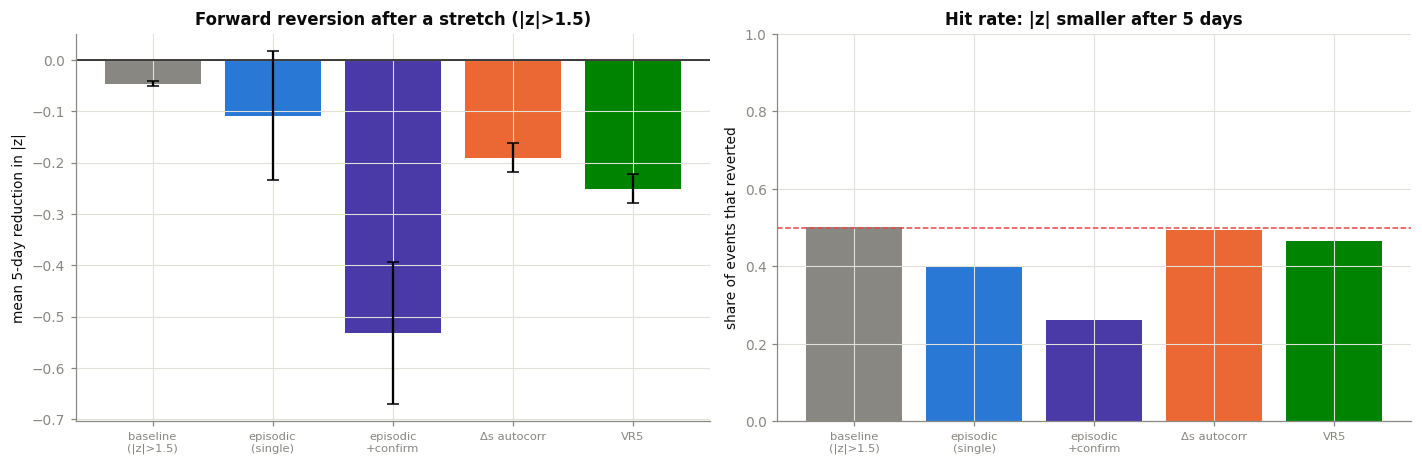

  baseline  : mean |z| reduction -0.046  hit-rate 50.1%  n=50644
  adf_gate  : mean |z| reduction -0.108  hit-rate 40.0%  n=190
  adf_conf  : mean |z| reduction -0.531  hit-rate 26.1%  n=115
  ac1       : mean |z| reduction -0.190  hit-rate 49.3%  n=2372
  vr5       : mean |z| reduction -0.251  hit-rate 46.5%  n=2681


In [6]:
K = 5; ZENT = TN.EPISODE_Z_ENTRY; GAP = TN.EPISODE_CONFIRM_GAP
methods = ["baseline","adf_gate","adf_conf","ac1","vr5"]
recs = {m: [] for m in methods}
for s in starts:
    f = s + W - 1                                  # window's last day index
    if f + K >= ndays: break
    beta, mu, r = build_spreads(LP[:, s:s+W]); mm = mr_measures(r)
    std = r.std(1) + 1e-12
    z_now = r[:,-1]/std
    raw_fwd = LP[PI, f+K] - beta*LP[PJ, f+K]       # forward raw spread, same beta
    z_fwd = (raw_fwd - mu)/std                     # centre by the window spread mean
    reduce = np.abs(z_now) - np.abs(z_fwd)         # +ve => reverted toward the mean
    stretched = np.abs(z_now) > ZENT
    if s-GAP >= 0:                                 # confirmation window (GAP earlier)
        _,_,rp = build_spreads(LP[:, s-GAP:s-GAP+W]); adf_prior = mr_measures(rp)["adf_t"]
    else:
        adf_prior = np.zeros(NP)
    gate = mm["adf_t"] < TN.EPISODE_ADF_T
    conf = gate & (adf_prior < TN.EPISODE_CONFIRM_T)
    recs["baseline"].append(reduce[stretched])
    recs["adf_gate"].append(reduce[stretched & gate])
    recs["adf_conf"].append(reduce[stretched & conf])
    recs["ac1"].append(reduce[stretched & (mm["ac1"] < crit["ac1"])])
    recs["vr5"].append(reduce[stretched & (mm["vr5"] < crit["vr5"])])
agg = {m: np.concatenate(v) if len(v) else np.array([]) for m,v in recs.items()}

lab5 = {"baseline":f"baseline\n(|z|>{ZENT})","adf_gate":"episodic\n(single)",
        "adf_conf":"episodic\n+confirm","ac1":"Δs autocorr","vr5":"VR5"}
col5 = {"baseline":MUTED,"adf_gate":BLUE,"adf_conf":VIOLET,"ac1":ORANGE,"vr5":GREEN}
bx = np.arange(len(methods))
means = [agg[m].mean() if agg[m].size else 0 for m in methods]
sems  = [agg[m].std()/np.sqrt(max(agg[m].size,1)) if agg[m].size else 0 for m in methods]
hit   = [(agg[m]>0).mean() if agg[m].size else 0 for m in methods]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].bar(bx, means, yerr=sems, color=[col5[m] for m in methods], capsize=4)
ax[0].axhline(0, color=INK, lw=1); ax[0].set_xticks(bx)
ax[0].set_xticklabels([lab5[m] for m in methods], fontsize=7.5)
ax[0].set_ylabel(f"mean {K}-day reduction in |z|")
ax[0].set_title(f"Forward reversion after a stretch (|z|>{ZENT})")
ax[1].bar(bx, hit, color=[col5[m] for m in methods]); ax[1].axhline(0.5, color=RED, ls="--", lw=1)
ax[1].set_xticks(bx); ax[1].set_xticklabels([lab5[m] for m in methods], fontsize=7.5)
ax[1].set_ylabel("share of events that reverted"); ax[1].set_ylim(0,1)
ax[1].set_title(f"Hit rate: |z| smaller after {K} days")
fig.tight_layout(); plt.show()
for m in methods:
    if agg[m].size:
        print(f"  {m:10s}: mean |z| reduction {agg[m].mean():+.3f}  hit-rate {(agg[m]>0).mean():.1%}  n={agg[m].size}")
    else:
        print(f"  {m:10s}: no events")

## 6 · Synthesis — for you to weigh

**On short-lived episodes (§3).** At a small window the reversion flag is
dominated by short episodes — read the median episode duration and the "one-shot"
share off the plot. The ADF gate and the autocorrelation gates differ in how
long-lived their flags are; a technique whose flags cluster into longer runs is
detecting steadier structure, one dominated by single-window flashes is mostly
catching transients (which cost turnover if traded).

**On autocorrelation vs the p-value (§2, §5).**
- `ac1` (lag-1 autocorr of Δspread) and `VR` flag a partly-overlapping but
  distinct set from the ADF gate — §2 shows pairs the gate rejects that these call
  reverting. Whether that extra set is signal or noise is answered in §5.
- §5 is the decisive panel: it measures whether each "reverting" flag is actually
  followed by `|z|` shrinking. Compare each filter's mean reduction and hit-rate to
  the baseline. A filter only earns its place if it beats the baseline.
- §5 also isolates the file's **confirmation** step: if `+confirm` beats the single
  episodic gate on hit-rate (at the cost of fewer events), the causal double-check
  is doing real work; if not, `EPISODE_CONFIRM_*` is just shrinking the sample.

**On window length (§4).** Detection power collapses as the window shrinks; the
power curves say how short each technique can go before a genuine φ=0.9 spread is
invisible. This bounds how "small" a runtime window can usefully be.

**Open questions for you.**
1. Is the extra set that autocorrelation flags (but ADF rejects) actually
   predictive (§5), or just more turnover?
2. Which measure keeps the most detection power at the shortest window you'd
   trade (§4)?
3. Would requiring a *persistent* flag (episode length ≥ 2-3 windows, §3) filter
   out the transient flashes without killing the real signal?
4. Do `ac1`/`VR` add value **on top of** the ADF gate (union/intersection), rather
   than as a replacement?